# Night Shift ML: dimensionality reduction of Pockets' inputs (PCA and t-SNE)

<a href="https://colab.research.google.com/github/Jesu0809/machine-learning-final-project/blob/main/training/notebooks/dimensionality_reduction.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Machine Learning, Universidad de Cundinamarca. Jesús David Nuncira Ortiz and Miguel Moreno Arenas.**

Pockets, the clown who hunts the player in *Night Shift*, decides every move with a neural network trained with
reinforcement learning (PPO, Unity ML-Agents). The network reads **100 numbers** that describe what Pockets knows
(his room, the noises he remembers, where he last saw the player, which rooms he has not checked, ...) and outputs a
probability for each of its 17 actions.

In this notebook we study that 100-dimensional input space with two dimensionality reduction techniques:

1. **PCA** (linear): how many directions explain the inputs, and what those directions mean.
2. **t-SNE** (non-linear): whether situations that lead to the same decision form groups.
3. **Effect on the model**: we compress the inputs to *k* principal components, give the reconstructed inputs to the
   real trained network and measure how many of its decisions change. We also train a small surrogate classifier on
   *k* components to see how much of the decision is predictable from a reduced representation.

The network and its exact preprocessing come from the project repository (`web/freddy_brain.py` and the exported
weights `web/data/FreddyPolicy.bytes`), the same code the website runs.

## 1. Setup: download the trained network from the repository

In [1]:
import os, urllib.request

BASE = "https://raw.githubusercontent.com/Jesu0809/machine-learning-final-project/main/web/"
os.makedirs("data", exist_ok=True)
for remote, local in [("freddy_brain.py", "freddy_brain.py"), ("data/FreddyPolicy.bytes", "data/FreddyPolicy.bytes")]:
    if not os.path.exists(local):
        urllib.request.urlretrieve(BASE + remote, local)
print(os.path.getsize("freddy_brain.py"), "bytes of code,", os.path.getsize("data/FreddyPolicy.bytes"), "bytes of weights")

8710 bytes of code, 384100 bytes of weights


In [2]:
import random, warnings
import numpy as np
# macOS Accelerate can print spurious floating point warnings in matrix products; results are exact.
warnings.filterwarnings("ignore", category=RuntimeWarning)
import matplotlib.pyplot as plt
import freddy_brain as brain

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("Network layers:", brain.network_info())
print("Rooms:", brain.ROOM_COUNT, "| actions:", brain.ACTION_COUNT, "| inputs:", brain.OBS_SIZE)

Network layers: [100, 256, 256, 17]
Rooms: 13 | actions: 17 | inputs: 100


## 2. The data: situations Pockets can be in

There is no fixed dataset in reinforcement learning: the data are the situations the agent meets. We generate
**3,000 situations** with a seeded sampler that varies everything the network reads (his room, up to two remembered
noises, a possible sighting, which rooms are stale, night progress, objectives, sense readiness). Each situation is
turned into the 100 inputs by `brain.observations()`, exactly as in the game, and labelled with the action the trained
network chooses.

In [3]:
def random_situation(rng):
    rooms = brain.ROOM_COUNT
    room = rng.randrange(rooms)
    s = {"freddy_room": room, "noises": {}, "night_progress": round(rng.random(), 2),
         "objectives": round(rng.random() * 0.8, 2), "sense_ready": rng.random() < 0.6}
    for _ in range(rng.choice((0, 0, 1, 1, 2))):
        s["noises"][str(rng.randrange(rooms))] = rng.choice((1, 2, 3))
    if rng.random() < 0.4:
        s["last_seen_room"] = rng.randrange(rooms)
        s["seconds_since_seen"] = rng.randrange(5, 200)
    s["rooms_not_checked"] = sorted(rng.sample(range(rooms), rng.randrange(3, rooms)))
    if rng.random() < 0.15:
        s["sees_player"] = True
    return s

def kind_of(index, room):
    if index == brain.SENSE:
        return "Sense"
    if index >= brain.ROOM_COUNT:
        return "Search a spot"
    return "Stay and listen" if index == room else "Move to a room"

rng = random.Random(2026)
situations = [random_situation(rng) for _ in range(3000)]
X = np.array([brain.observations(s) for s in situations])
decisions = [brain.decide(s) for s in situations]
action = np.array([d["chosen"]["index"] for d in decisions])
kind = np.array([kind_of(a, s["freddy_room"]) for a, s in zip(action, situations)])
KINDS = ["Move to a room", "Stay and listen", "Search a spot", "Sense"]
COLORS = {"Move to a room": "#2b7bba", "Stay and listen": "#7b8399", "Search a spot": "#f2a33a", "Sense": "#d1323b"}
print("X shape:", X.shape)
for k in KINDS:
    print(f"{k:16s} {np.sum(kind == k):5d}")

X shape:

 (3000, 100)
Move to a room    2249
Stay and listen     69
Search a spot       99
Sense              583


### Feature names and data quality

The 100 inputs are organised in blocks. All values are already scaled to [0, 1] by fixed constants (÷3, ÷60, ÷240), so
there is no missing value to impute and no scaler to fit. Several inputs never vary in this sample (for example the
route features of rooms that are never next to Pockets in a given state); they carry no information for PCA.

In [4]:
R = brain.ROOM_COUNT
names = ([f"room={r}" for r in brain.ROOMS] + [f"noise@{r}" for r in brain.ROOMS] + [f"seen@{r}" for r in brain.ROOMS]
         + ["since_seen"] + [f"unchecked@{r}" for r in brain.ROOMS] + ["sees_now", "objectives", "progress"]
         + [f"searched_spot{i}" for i in range(3)] + ["sense_ready"] + [f"sensed@{r}" for r in brain.ROOMS] + ["since_sensed"]
         + [f"to_noise@{r}" for r in brain.ROOMS] + [f"to_sighting@{r}" for r in brain.ROOMS])
assert len(names) == X.shape[1] == 100
print("min / max:", X.min(), X.max(), "| missing values:", int(np.isnan(X).sum()))
print("share of zeros:", round(float((X == 0).mean()), 3))
constant = X.std(axis=0) < 1e-9
print("constant inputs:", int(constant.sum()), [n for n, c in zip(names, constant) if c][:8])

min / max: 0.0 1.0 | missing values: 0
share of zeros: 0.801
constant inputs: 17 ['searched_spot0', 'searched_spot1', 'searched_spot2', 'sensed@Watch Office', 'sensed@Prop Workshop', 'sensed@Dressing Rooms', 'sensed@Backstage Hall', 'sensed@Trunk Store']


## 3. PCA

PCA finds orthogonal directions of maximum variance. Because every input is already on the same [0, 1] scale, we only
**center** the data (standardizing would inflate rare one-hot inputs). The PCA is fitted on a training split only and
applied to the test split, the same discipline we use for any preprocessing.

50% of the variance needs 13 components
80% of the variance needs 31 components
90% of the variance needs 46 components
95% of the variance needs 57 components
PC1, PC2: [0.07  0.051]


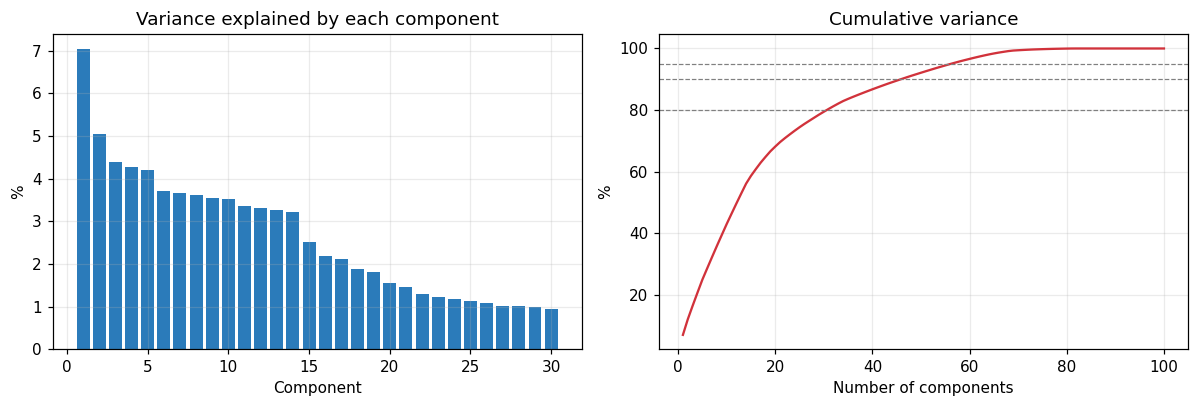

In [5]:
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

idx_train, idx_test = train_test_split(np.arange(len(X)), test_size=0.3, random_state=0, stratify=kind)
pca = PCA().fit(X[idx_train])
var = pca.explained_variance_ratio_
cum = np.cumsum(var)
for target in (0.5, 0.8, 0.9, 0.95):
    print(f"{target:.0%} of the variance needs {int(np.searchsorted(cum, target)) + 1} components")
print("PC1, PC2:", var[:2].round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(range(1, 31), var[:30] * 100, color="#2b7bba")
ax[0].set_title("Variance explained by each component"); ax[0].set_xlabel("Component"); ax[0].set_ylabel("%")
ax[1].plot(range(1, 101), cum * 100, color="#d1323b")
for t in (80, 90, 95):
    ax[1].axhline(t, ls="--", lw=0.8, color="gray")
ax[1].set_title("Cumulative variance"); ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

In [6]:
for pc in range(2):
    order = np.argsort(-np.abs(pca.components_[pc]))[:6]
    print(f"PC{pc + 1}:", ", ".join(f"{names[i]} ({pca.components_[pc][i]:+.2f})" for i in order))

PC1: unchecked@The Big Ring (+0.31), unchecked@Winter Garden (+0.30), unchecked@Ringside Lounge (+0.30), unchecked@Trunk Store (+0.30), unchecked@The Midway (+0.29), unchecked@Ticket Lobby (+0.29)
PC2: to_noise@Backstage Hall (+0.50), to_sighting@Backstage Hall (+0.31), unchecked@Dressing Rooms (-0.30), unchecked@Concessions (-0.26), unchecked@Ringside Lounge (+0.22), to_noise@Concessions (-0.20)


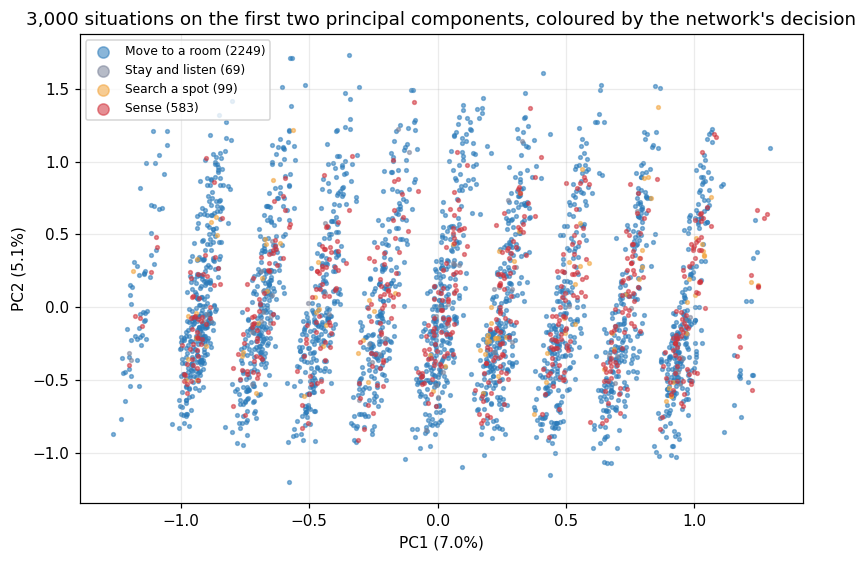

In [7]:
Z = pca.transform(X)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for k in KINDS:
    m = kind == k
    ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.55, color=COLORS[k], label=f"{k} ({m.sum()})")
ax.set_xlabel(f"PC1 ({var[0]:.1%})"); ax.set_ylabel(f"PC2 ({var[1]:.1%})")
ax.set_title("3,000 situations on the first two principal components, coloured by the network's decision")
ax.legend(markerscale=3, fontsize=8); plt.tight_layout(); plt.show()

## 4. t-SNE

t-SNE keeps neighbourhoods instead of variance: points that are close in 100 dimensions stay close in 2. It is only a
visualisation (it cannot transform new points), so we run it on 2,000 situations with three perplexities and measure
how well each 2-D map preserves the original neighbourhoods with the **trustworthiness** score (1 = perfect).

t-SNE perplexity 5: trustworthiness 0.956


t-SNE perplexity 30: trustworthiness 0.968


t-SNE perplexity 50: trustworthiness 0.971


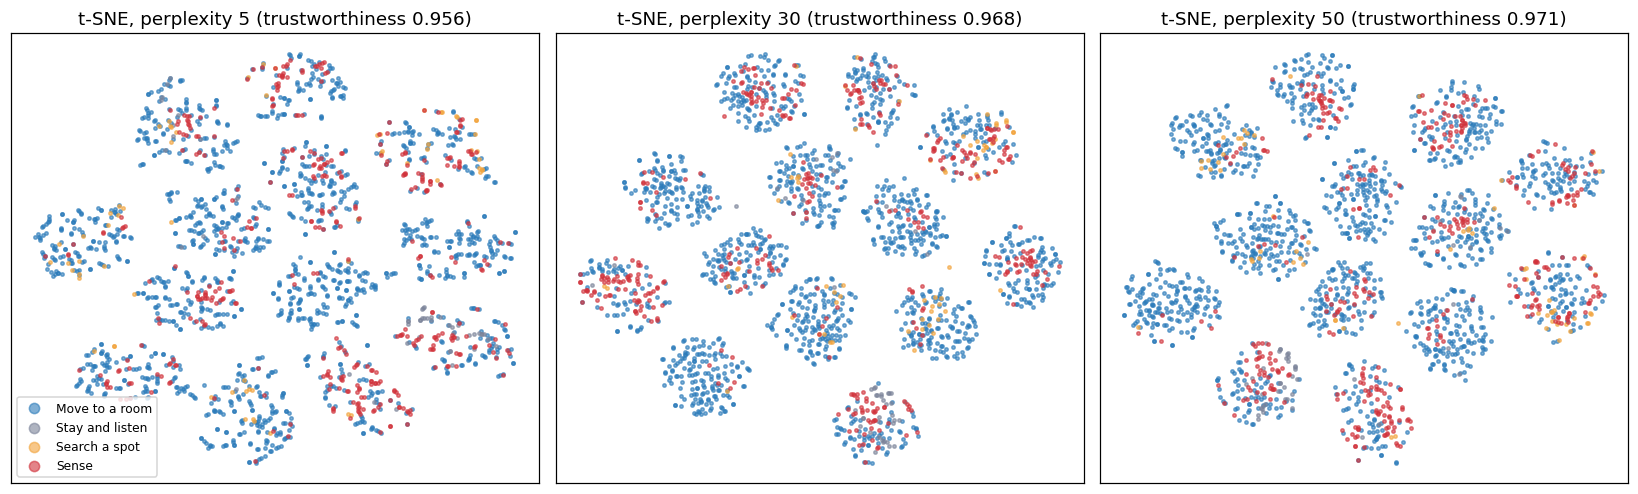

PCA 2-D trustworthiness: 0.703


In [8]:
from sklearn.manifold import TSNE, trustworthiness

sub = np.arange(2000)
results = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, perplexity in zip(axes, (5, 30, 50)):
    emb = TSNE(n_components=2, perplexity=perplexity, init="pca", learning_rate="auto", random_state=0).fit_transform(X[sub])
    results[perplexity] = emb
    for k in KINDS:
        m = kind[sub] == k
        ax.scatter(emb[m, 0], emb[m, 1], s=5, alpha=0.6, color=COLORS[k], label=k)
    tw = trustworthiness(X[sub], emb, n_neighbors=10)
    print(f"t-SNE perplexity {perplexity}: trustworthiness {tw:.3f}")
    ax.set_title(f"t-SNE, perplexity {perplexity} (trustworthiness {tw:.3f})")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()
print("PCA 2-D trustworthiness:", round(trustworthiness(X[sub], Z[sub, :2], n_neighbors=10), 3))

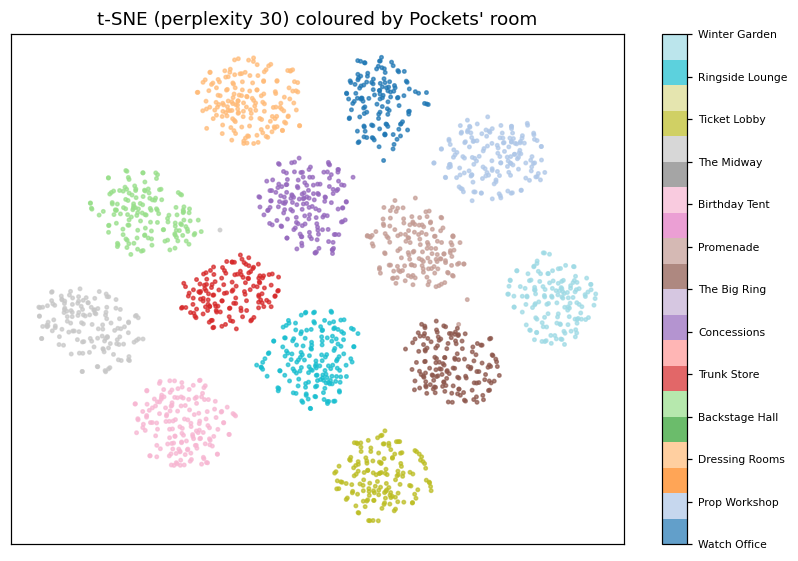

In [9]:
emb = results[30]
fig, ax = plt.subplots(figsize=(7.5, 5.2))
room = np.array([s["freddy_room"] for s in situations])[sub]
sc = ax.scatter(emb[:, 0], emb[:, 1], s=5, c=room, cmap="tab20", alpha=0.7)
ax.set_title("t-SNE (perplexity 30) coloured by Pockets' room"); ax.set_xticks([]); ax.set_yticks([])
cb = plt.colorbar(sc, ticks=range(R)); cb.ax.set_yticklabels(brain.ROOMS, fontsize=7)
plt.tight_layout(); plt.show()

## 5. How the reduction affects the model

**(a) The real network on compressed inputs.** We project each test situation onto *k* principal components,
reconstruct the 100 inputs from them and run the trained network on the reconstruction (with the same action mask).
If its decision does not change, those *k* components kept everything the network uses.

**(b) A surrogate classifier.** A logistic regression learns to predict the kind of decision (move, stay, search,
sense) from *k* components. PCA and the classifier are fitted on the training split only.

In [10]:
def forward(x, situation):
    with np.errstate(all="ignore"):
        for i, (w, b) in enumerate(brain._LAYERS):
            x = w @ x + b
            if i < len(brain._LAYERS) - 1:
                x = x / (1.0 + np.exp(-x))
    legal = brain.legal_actions(situation)
    return int(np.argmax(np.where(legal, x, -np.inf)))

ks = [2, 5, 10, 20, 30, 46, 60, 80, 100]
agreement = []
for k in ks:
    p = PCA(n_components=k).fit(X[idx_train])
    rec = p.inverse_transform(p.transform(X[idx_test]))
    same = np.mean([forward(rec[j], situations[i]) == action[i] for j, i in enumerate(idx_test)])
    agreement.append(same)
    print(f"k = {k:3d}: the network keeps {same:.1%} of its decisions")

k =   2: the network keeps 56.3% of its decisions
k =   5: the network keeps 64.7% of its decisions
k =  10: the network keeps 67.2% of its decisions
k =  20: the network keeps 79.6% of its decisions


k =  30: the network keeps 84.2% of its decisions
k =  46: the network keeps 89.7% of its decisions
k =  60: the network keeps 93.0% of its decisions
k =  80: the network keeps 99.8% of its decisions
k = 100: the network keeps 100.0% of its decisions


k =   2: surrogate accuracy 74.9%
k =   5: surrogate accuracy 75.1%
k =  10: surrogate accuracy 76.6%
k =  20: surrogate accuracy 78.4%
k =  30: surrogate accuracy 83.3%
k =  46: surrogate accuracy 86.0%
k =  60: surrogate accuracy 87.8%


k =  80: surrogate accuracy 88.1%
k = 100: surrogate accuracy 88.1%
Majority-class baseline: 74.9%


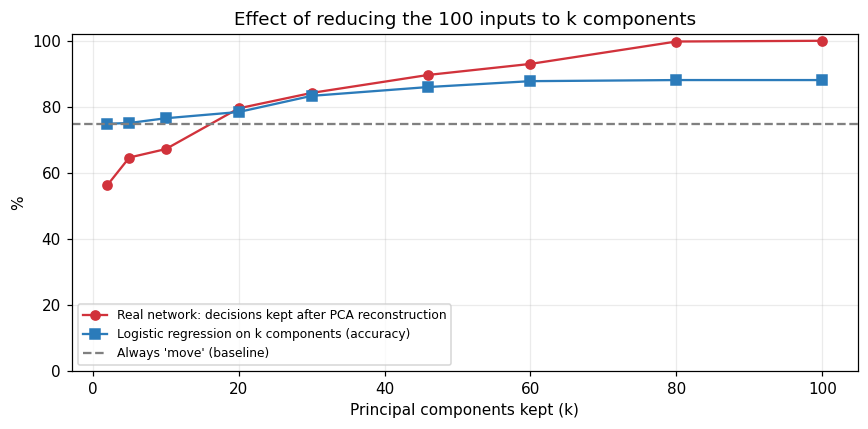

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

surrogate = []
for k in ks:
    p = PCA(n_components=k).fit(X[idx_train])
    clf = LogisticRegression(max_iter=3000).fit(p.transform(X[idx_train]), kind[idx_train])
    surrogate.append(accuracy_score(kind[idx_test], clf.predict(p.transform(X[idx_test]))))
    print(f"k = {k:3d}: surrogate accuracy {surrogate[-1]:.1%}")
baseline = np.mean(kind[idx_test] == "Move to a room")
print(f"Majority-class baseline: {baseline:.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, np.array(agreement) * 100, marker="o", color="#d1323b", label="Real network: decisions kept after PCA reconstruction")
ax.plot(ks, np.array(surrogate) * 100, marker="s", color="#2b7bba", label="Logistic regression on k components (accuracy)")
ax.axhline(baseline * 100, ls="--", color="gray", label="Always 'move' (baseline)")
ax.set_xlabel("Principal components kept (k)"); ax.set_ylabel("%"); ax.set_ylim(0, 102)
ax.set_title("Effect of reducing the 100 inputs to k components"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Conclusions

The numbers printed above support these conclusions (they are discussed in the project report):

* **PCA:** the variance is spread over many directions; dozens of components are needed for 90%, because the inputs
  are mostly independent one-hot blocks (room, last sighting, sense) with little redundancy.
* **t-SNE:** the 2-D maps group situations mainly by Pockets' room, the strongest input; decisions of the same kind
  appear in several separate islands, so a decision is not a single region of the input space.
* **Effect on the model:** with few components the real network changes many of its decisions; it only keeps almost
  all of them when most components are kept. The surrogate classifier also needs many components to approach its
  full-input accuracy. The network uses fine, non-linear detail of the inputs.
* **Decision for the project:** keep the 100 inputs (no PCA before the network). Dimensionality reduction is used for
  analysis and for monitoring summaries, not as preprocessing. The game and the website feed the network the full
  vector, and the AI inspector can explain every input to the player.